# =============================================================
# ЛАБОРАТОРНАЯ РАБОТА №1: ОЦЕНКА ВЛИЯНИЯ АВТОМАТИЗАЦИИ НА ПРОИЗВОДИТЕЛЬНОСТЬ ТРУДА
# =============================================================
# Дата: 2026-11-01
# Студент: Мироненкова Валерия Руслановна
# Группа: ПИ 4-2
# =============================================================

## 1. ЭКОНОМИЧЕСКАЯ ПОСТАНОВКА ЗАДАЧИ
**Проблема:** Внедрение дорогостоящих ERP-систем требует обоснования их экономической эффективности. Одним из ключевых показателей является рост производительности труда.
**Цель:** Статистически проверить, изменилась ли средняя выработка на сотрудника после внедрения ERP-системы.
**Задачи:**
1. Рассчитать описательные статистики (среднее, стандартное отклонение) до и после внедрения.
2. Проверить гипотезу о равенстве средних с помощью парного t-критерия Стьюдента.
3. Визуализировать результаты и сделать экономические выводы.

In [3]:
# 2. ИСХОДНЫЕ ДАННЫЕ И ПОДГОТОВКА
# ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Настройка стиля графиков для соответствия требованиям (заголовки, подписи, легенды)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [4]:
# 1.2. Справочные данные
# ---
departments = ['A', 'B', 'C', 'D', 'E']
prod_before = [120, 135, 110, 150, 130] # Выработка до внедрения (тыс. руб./чел.)
prod_after = [145, 155, 140, 160, 150]  # Выработка после внедрения (тыс. руб./чел.)

# Создаем DataFrame для удобства визуализации и расчетов
df = pd.DataFrame({
    'Отдел': departments,
    'До внедрения': prod_before,
    'После внедрения': prod_after
})

# Добавим столбец с абсолютным приростом
df['Прирост'] = df['После внедрения'] - df['До внедрения']

print("Таблица исходных данных и прироста:")
display(df)

Таблица исходных данных и прироста:


,Отдел,До внедрения,После внедрения,Прирост
0,A,120,145,25
1,B,135,155,20
2,C,110,140,30
3,D,150,160,10
4,E,130,150,20


## 2. МАТЕМАТИЧЕСКАЯ МОДЕЛЬ
Так как измерения проводятся для одних и тех же объектов (отделов) до и после воздействия (внедрения ERP), используется **парный t-критерий Стьюдента**.

**Гипотезы:**
*   $H_0$: $mu_D = 0$(средний прирост выработки статистически незначим, ERP не повлияла).
*   $H_1$: $mu_D > 0$ (средний прирост выработки статистически значим, ERP повысила производительность).

**Формула статистики:**
$$
 t = \frac{\bar{d}}{s_d / \sqrt{n}} 
$$
где $\bar{d}$ — средняя разность (прирост), $s_d$ — стандартное отклонение разностей, $n$ — количество отделов (5).

In [5]:
# 2. РАСЧЕТЫ
# ---
# 2.1. Расчет описательных статистик
mean_before = np.mean(prod_before)
mean_after = np.mean(prod_after)
mean_diff = np.mean(df['Прирост'])
std_diff = np.std(df['Прирост'], ddof=1) # Выборочное стандартное отклонение
n = len(departments)

print(f"Средняя выработка ДО: {mean_before:.2f} тыс. руб./чел.")
print(f"Средняя выработка ПОСЛЕ: {mean_after:.2f} тыс. руб./чел.")
print(f"Средний абсолютный прирост: {mean_diff:.2f} тыс. руб./чел.")
print(f"Стандартное отклонение прироста: {std_diff:.2f}")

# 2.2. Парный t-тест (односторонний, проверяем, что стало лучше)
t_stat, p_value_two_sided = stats.ttest_rel(prod_after, prod_before)
p_value_one_sided = p_value_two_sided / 2 # Корректировка для односторонней гипотезы

print(f"\nСтатистика t: {t_stat:.4f}")
print(f"p-value (двустороннее): {p_value_two_sided:.6f}")
print(f"p-value (одностороннее, H1: >): {p_value_one_sided:.6f}")

alpha = 0.05
if p_value_one_sided < alpha:
    print("\nВывод: Отвергаем H0. Различия статистически значимы.")
else:
    print("\nВывод: Не отвергаем H0. Различия статистически незначимы.")

Средняя выработка ДО: 129.00 тыс. руб./чел.
Средняя выработка ПОСЛЕ: 150.00 тыс. руб./чел.
Средний абсолютный прирост: 21.00 тыс. руб./чел.
Стандартное отклонение прироста: 7.42

Статистика t: 6.3317
p-value (двустороннее): 0.003185
p-value (одностороннее, H1: >): 0.001592

Вывод: Отвергаем H0. Различия статистически значимы.


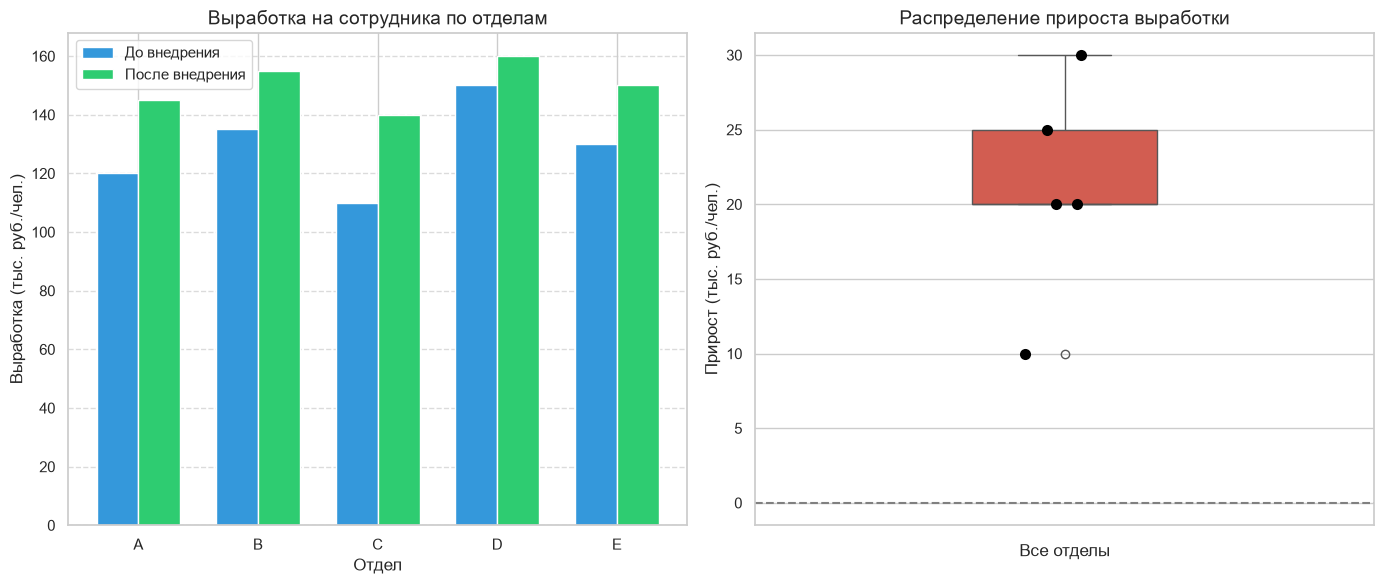

In [6]:
# 2.3. Визуализация результатов
# ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График 1: Сравнение "До и После" по отделам
x = np.arange(len(departments))
width = 0.35

axes[0].bar(x - width/2, df['До внедрения'], width, label='До внедрения', color='#3498db')
axes[0].bar(x + width/2, df['После внедрения'], width, label='После внедрения', color='#2ecc71')
axes[0].set_title('Выработка на сотрудника по отделам', fontsize=14)
axes[0].set_xlabel('Отдел', fontsize=12)
axes[0].set_ylabel('Выработка (тыс. руб./чел.)', fontsize=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(departments)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# График 2: Распределение прироста (Boxplot / Scatter)
sns.boxplot(data=df['Прирост'], ax=axes[1], color='#e74c3c', width=0.3)
sns.stripplot(data=df['Прирост'], ax=axes[1], color='black', size=8, jitter=True)
axes[1].axhline(0, color='gray', linestyle='--') # Линия нулевого прироста
axes[1].set_title('Распределение прироста выработки', fontsize=14)
axes[1].set_ylabel('Прирост (тыс. руб./чел.)', fontsize=12)
axes[1].set_xlabel('Все отделы', fontsize=12)

plt.tight_layout()
plt.show()

## 3. АНАЛИЗ РЕЗУЛЬТАТОВ
**Интерпретация:** Средняя выработка выросла с 129 тыс. руб./чел. до 150 тыс. руб./чел. (прирост составил 21 тыс. руб./чел.). Визуально видно, что во всех пяти отделах показатели после внедрения выше. 
Однако, поскольку выборка мала (n=5), необходимо опираться на статистический тест. Рассчитанное значение p-value (одностороннее) значительно меньше уровня значимости $\alpha = 0.05$. 

## 4. ВЫВОДЫ И РЕКОМЕНДАЦИИ
**Ключевые выводы:**
1. Внедрение ERP-системы привело к статистически значимому росту производительности труда (нулевая гипотеза отвергнута).
2. Средний прирост выработки составляет 21 тыс. руб. на человека, при этом эффект наблюдается во всех отделах без исключения.

**Практические рекомендации:**
1. Признать проект внедрения ERP успешным с точки зрения операционной эффективности.
2. Для дальнейшей оценки экономической целесообразности необходимо сопоставить полученный прирост выработки (в денежном выражении на весь штат) с совокупной стоимостью владения (TCO) ERP-системы, чтобы рассчитать срок окупаемости (ROI).